# 1. Input posteriors

This is the first of three notebooks that reproduce the results of *Combining the Mass–Radius Posteriors of PSR J0030+0451 Allowing for Unknown Model Systematics*:

1. **Input posteriors** (this notebook): the eight published mass–radius posteriors that are combined.
2. **Combined posterior**: the combination method, step by step, and the headline result.
3. **Figures and consistency**: the paper's figures and the consistency probability of each input.

All three run from the repository root and import the small `j0030` package, which holds the method.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt

from j0030 import method, plotting

## The eight inputs

Each file in `data/` holds posterior samples published by the original analysis, as two columns: gravitational mass $M$ (in $M_\odot$) and equatorial radius $R$ (in km). See the README for sources and citations.

| Key | Analysis | Hot-spot model |
|---|---|---|
| `ST_PST19` | Riley et al. (2019) | ST+PST |
| `ST_PDT`, `ST_PST`, `PDT_U`, `ST_U` | Vinciguerra et al. (2024) | ST+PDT, ST+PST, PDT-U, ST-U |
| `2spot`, `3spot` | Miller et al. (2019) | two and three oval spots |
| `PDT_U26` | Kini et al. (2026) | PDT-U |

All eight analyse NICER data of the same pulsar, and most share the same photons. The combination in notebook 2 has to allow for that.

## Summary of each input

Medians and central 68% intervals of $M$, $R$ and the compactness $C = GM/(Rc^2)$, computed directly from the samples (the input rows of the paper's summary table). The last column is the correlation between $M$ and $C$.

In [2]:
samples = {key: method.load_samples(key) for key in method.MODEL_KEYS}

print(f"{'input':<24}{'samples':>9}{'M (Msun)':>20}{'R (km)':>21}{'C':>23}{'corr(M, C)':>12}")
for key, (M, R) in samples.items():
    C = method.K_KM * M / R
    print(f"{method.label(key):<24}{len(M):>9}"
          f"{method.fmt(method.sample_quantiles(M), 2):>20}"
          f"{method.fmt(method.sample_quantiles(R), 2):>21}"
          f"{method.fmt(method.sample_quantiles(C), 3):>23}"
          f"{np.corrcoef(M, C)[0, 1]:>12.2f}")

input                     samples            M (Msun)               R (km)                      C  corr(M, C)
Riley19: ST+PST              7852    1.29 +0.17/-0.16    12.57 +1.37/-1.29    0.153 +0.011/-0.014        0.56
Vinciguerra24: ST+PDT       12008    1.40 +0.13/-0.12    11.71 +0.87/-0.83    0.177 +0.006/-0.007        0.57
Vinciguerra24: ST+PST       11795    1.93 +0.10/-0.12    15.23 +0.52/-0.84    0.188 +0.006/-0.007        0.58
Vinciguerra24: PDT-U        12832    1.70 +0.18/-0.19    14.44 +0.88/-1.05    0.179 +0.011/-0.022        0.81
Vinciguerra24: ST-U         69355    1.88 +0.13/-0.19    15.12 +0.64/-1.31    0.186 +0.007/-0.010        0.65
Miller19: 2spot            400000    1.44 +0.17/-0.16    13.27 +1.30/-1.15    0.160 +0.009/-0.008        0.61
Miller19: 3spot           1000000    1.44 +0.15/-0.15    13.01 +1.25/-1.06    0.163 +0.008/-0.009        0.51
Kini26: PDT-U              168884    1.43 +0.20/-0.17    12.68 +1.31/-1.04    0.169 +0.011/-0.014        0.72


## Mass–radius and mass–compactness planes

Pulse-profile modelling constrains the compactness more tightly than $M$ or $R$ separately, so each input is a narrow band in $C$ and a long ridge along lines of constant $C$ in the $M$–$R$ plane. The inputs agree only partly: some models prefer $M \approx 1.4\,M_\odot$, while Vinciguerra24 ST+PST and ST-U sit near $1.9\,M_\odot$.

For this reason the combination in notebook 2 is carried out in $(M, C)$.

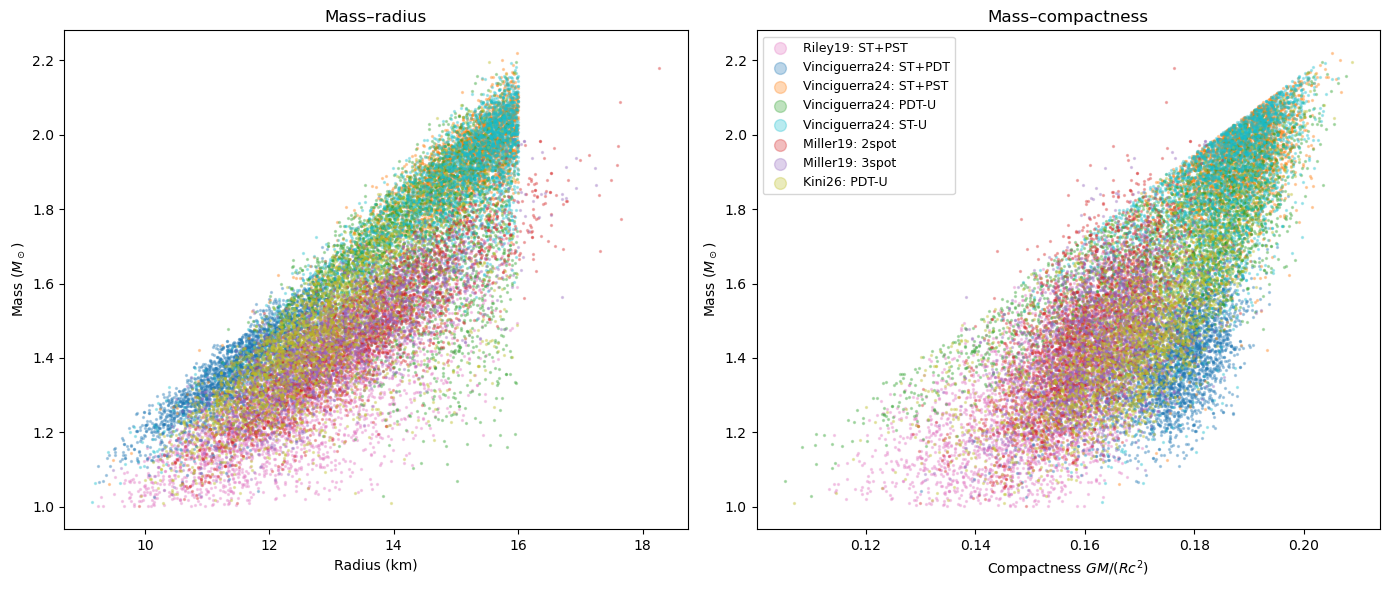

In [3]:
rng = np.random.default_rng(0)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))
for key, (M, R) in samples.items():
    idx = rng.choice(len(M), size=min(len(M), 3000), replace=False)
    meta = method.MODELS[key]
    ax1.scatter(R[idx], M[idx], s=2, alpha=0.3, color=meta["color"])
    ax2.scatter(method.K_KM * M[idx] / R[idx], M[idx], s=2, alpha=0.3, color=meta["color"],
                label=method.label(key))
ax1.set(xlabel="Radius (km)", ylabel=r"Mass ($M_\odot$)", title="Mass–radius")
ax2.set(xlabel=r"Compactness $GM/(Rc^2)$", ylabel=r"Mass ($M_\odot$)", title="Mass–compactness")
ax2.legend(markerscale=6, fontsize=9, loc="upper left")
plt.tight_layout()

Next: **`2_Combined_Posterior.ipynb`** combines these eight posteriors.